## u-Segment3D: Cellpose 2D slices aggregated into a 3D segmentation

This notebook adapts the u-Segment3D single-cell tracking example to the CellMot volumes.

> [u-Segment3D code](https://github.com/DanuserLab/u-segment3D) | [Cellpose code](https://github.com/MouseLand/cellpose)


In [ ]:
# !uv pip install u-segment3d --no-deps
# !uv pip install edt multiprocess "dask[distributed]" connected-components-3d

In [ ]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

### Init


In [ ]:
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import skimage.color as skcolor
import skimage.filters as skfilters
import skimage.morphology as skmorph
import skimage.segmentation as sksegmentation
from scipy import ndimage
from tqdm.auto import tqdm

sys.path.insert(0, "../src")

from cellpose import core, models
import cellpose.utils

In [ ]:
import segment3D.filters as uSegment3D_filters
import segment3D.flows as uSegment3D_flows
import segment3D.parameters as uSegment3D_params
import segment3D.segmentation as uSegment3D_segment
import segment3D.usegment3d as uSegment3D
import segment3D.watershed as uSegment3D_watershed

In [ ]:
from params import IMG_FOLDER, NODES_FOLDER, SCALE
from utils.metrics import match_frame_nodes
from utils.plot import *

## 1. Load and preprocess one 3D frame

In [ ]:
sample_name = "6bba_09961292"
frame = 56

# Input is one raw (z, y, x) uint16 frame.
img = np.load(IMG_FOLDER + f"{sample_name}_{frame}.npy")

nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")
gt = nodes.loc[nodes["t"] == frame, ["z", "y", "x"]].to_numpy()

print("image:", img.shape, img.dtype)
print("sparse GT nodes:", len(gt))

In [ ]:
# u-Segment3D normalizes contrast before fitting Cellpose on each XY slice.
img_preprocess = uSegment3D_filters.normalize(img, clip=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, projection, title in zip(
    axes,
    [img_preprocess.max(axis=0), img_preprocess.max(axis=1), img_preprocess.max(axis=2)],
    ["XY max projection", "XZ max projection", "YZ max projection"],
):
    ax.imshow(projection, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()

### 2. Run Cellpose slice-by-slice

In [ ]:
flow_threshold = 1
cellprob_threshold = 0.0
tile_norm_blocksize = 0


In [ ]:
model = models.CellposeModel(gpu=core.use_gpu())
print('GPU enabled:', core.use_gpu())

In [ ]:
all_probs_stack = np.asarray(all_probs_stack)
all_flows_stack = np.asarray(all_flows_stack)
all_masks_stack = np.asarray(all_masks_stack)
all_styles_stack = np.asarray(all_styles_stack)
all_params_diams = np.asarray(all_params_diams)

In [ ]:
%%time
masks, flows, styles = model.eval(
    img[..., None],
    batch_size=64,
    flow_threshold=flow_threshold,
    cellprob_threshold=cellprob_threshold,
    normalize={"tile_norm_blocksize": tile_norm_blocksize},
)


In [ ]:
for f in flows:
    print(f.shape)

In [134]:
# prob = flows[1][-1]
prob = flows[-1]
prob = 1.0 / (1 + np.exp(-prob))
# prob.min(), prob.max()

In [ ]:
# plt.imshow(prob[0], cmap='gray')

In [ ]:
aggregation_params = uSegment3D_params.get_2D_to_3D_aggregation_params()
aggregation_params["gradient_descent"]["n_iter"] = 100
aggregation_params["gradient_descent"]["gradient_decay"] = 0.01
aggregation_params["gradient_descent"]["momenta"] = 0.98
aggregation_params["combine_cell_probs"]["threshold_n_levels"] = 3
aggregation_params["combine_cell_probs"]["threshold_level"] = 0
aggregation_params["combine_cell_probs"]["min_prob_thresh"] = 0.1

postprocess_segment_params = uSegment3D_params.get_postprocess_segmentation_params()
postprocess_segment_params["size_filters"]["min_size"] = 15
postprocess_segment_params["flow_consistency"]["flow_threshold"] = 0.85

In [ ]:
# all_probs_stack = []
# all_flows_stack = []
# all_masks_stack = []
# all_styles_stack = []
# all_params_diams_range = []
# all_params_diams_score = []
# all_params_diams = []

# for z in tqdm(range(len(img_preprocess)), desc="u-Segment3D XY slices"):
#     im_slice = ndimage.median_filter(img_preprocess[z], size=3)

#     mask, flow, style = masks[z], [f[z] for f in flows], styles[z]

#     prob = flows[-1]
#     prob = 1.0 / (1 + np.exp(-prob))
    
#     # params, (all_probs, all_flows, all_styles) = (
#     #     uSegment3D_segment.apply_cellpose_model_2D_prob_slice(
#     #         im_slice,
#     #         model,
#     #         model_channels=cellpose_channels,
#     #         best_diam=cellpose_segment_params["best_diam"],
#     #         model_invert=cellpose_segment_params["model_invert"],
#     #         test_slice=cellpose_segment_params["test_slice"],
#     #         diam_range=cellpose_segment_params["diam_range"],
#     #         ksize=cellpose_segment_params["ksize"],
#     #         smoothwinsize=cellpose_segment_params["smoothwinsize"],
#     #         hist_norm=cellpose_segment_params["hist_norm"],
#     #         kernel_size=cellpose_segment_params["histnorm_kernel_size"],
#     #         clip_limit=cellpose_segment_params["histnorm_clip_limit"],
#     #         use_edge=cellpose_segment_params["use_edge"],
#     #         use_prob_weighted_score=cellpose_segment_params["use_prob_weighted_score"],
#     #     )
#     # )

#     all_params_diams_range.append(params[0])
#     all_params_diams_score.append(params[1])
#     all_params_diams.append(params[2])

#     # Convert Cellpose logits to probabilities and normalize its XY flow field.
#     all_probs = np.clip(all_probs, -88.72, 88.72)
#     all_probs = 1.0 / (1.0 + np.exp(-all_probs))

#     all_flows = np.asarray(
#         [ndimage.gaussian_filter(channel, sigma=1) for channel in all_flows]
#     )
#     all_flows /= np.linalg.norm(all_flows, axis=0, keepdims=True) + 1e-20

#     thresholds = skfilters.threshold_multiotsu(
#         all_probs,
#         aggregation_params["combine_cell_probs"]["threshold_n_levels"],
#     )
#     threshold_level = aggregation_params["combine_cell_probs"]["threshold_level"]
#     prob_thresh = max(
#         int(thresholds[threshold_level] * 10) / 10.0,
#         aggregation_params["combine_cell_probs"]["min_prob_thresh"],
#     )
#     binary = all_probs >= prob_thresh

#     labels_2d, _, _, _ = uSegment3D_watershed.gradient_watershed2D_binary(
#         binary,
#         gradient_img=all_flows.transpose(1, 2, 0),
#         momenta=aggregation_params["gradient_descent"]["momenta"],
#         gradient_decay=aggregation_params["gradient_descent"]["gradient_decay"],
#         n_iter=aggregation_params["gradient_descent"]["n_iter"],
#     )

#     labels_2d, _, _ = uSegment3D_flows.remove_bad_flow_masks_2D(
#         labels_2d,
#         flow=all_flows,
#         flow_threshold=postprocess_segment_params["flow_consistency"]["flow_threshold"],
#         dtform_method=postprocess_segment_params["flow_consistency"]["dtform_method"],
#         fixed_point_percentile=postprocess_segment_params["flow_consistency"]["edt_fixed_point_percentile"],
#         n_processes=postprocess_segment_params["flow_consistency"]["n_cpu"],
#         power_dist=postprocess_segment_params["flow_consistency"]["power_dist"],
#         alpha=aggregation_params["combine_cell_gradients"]["alpha"],
#         filter_scale=aggregation_params["combine_cell_gradients"]["ksize"],
#     )
#     labels_2d = cellpose.utils.fill_holes_and_remove_small_masks(
#         labels_2d,
#         min_size=postprocess_segment_params["size_filters"]["min_size"],
#     )

#     all_probs_stack.append(all_probs)
#     all_flows_stack.append(all_flows)
#     all_masks_stack.append(labels_2d)
#     all_styles_stack.append(all_styles)

# all_probs_stack = np.asarray(all_probs_stack)
# all_flows_stack = np.asarray(all_flows_stack)
# all_masks_stack = np.asarray(all_masks_stack)
# all_styles_stack = np.asarray(all_styles_stack)
# all_params_diams = np.asarray(all_params_diams)

In [ ]:
# # Remove dim 2D regions using the global distribution of per-instance mean intensity.
# mean_intensities = []
# for z, labels_2d in enumerate(all_masks_stack):
#     label_ids = np.setdiff1d(np.unique(labels_2d), 0)
#     mean_intensities.extend(
#         ndimage.mean(img_preprocess[z], labels=labels_2d, index=label_ids)
#     )

# intensity_threshold = skfilters.threshold_otsu(np.asarray(mean_intensities))
# labels_xy_refine = all_masks_stack.copy()

# for z, labels_2d in enumerate(all_masks_stack):
#     for label_id in np.setdiff1d(np.unique(labels_2d), 0):
#         if img_preprocess[z][labels_2d == label_id].mean() <= intensity_threshold:
#             labels_xy_refine[z][labels_2d == label_id] = 0


In [ ]:
# # Inspect the refined 2D segmentation before 3D aggregation.
# z = int(np.median(gt[:, 0])) if len(gt) else len(img) // 2
# marked = sksegmentation.mark_boundaries(
#     np.dstack([img_preprocess[z]] * 3),
#     labels_xy_refine[z],
#     color=(0, 1, 0),
#     mode="thick",
# )

# plt.figure(figsize=(7, 7))
# plt.imshow(marked)
# if len(gt):
#     gt_z = gt[gt[:, 0] == z]
#     plt.scatter(gt_z[:, 2], gt_z[:, 1], s=80, facecolors="none", edgecolors="white")
# plt.title(f"Refined Cellpose/u-Segment3D labels, z={z}")
# plt.axis("off")
# plt.show()

## 3. Aggregate the XY segmentations into one 3D instance volume

In [193]:
aggregation_params = uSegment3D_params.get_2D_to_3D_aggregation_params()

aggregation_params['combine_cell_probs']['ksize'] = 1
aggregation_params['combine_cell_probs']['alpha'] = 0.5 
aggregation_params['combine_cell_probs']['smooth_sigma'] = 0 # add post smoothing too after combine 
aggregation_params['combine_cell_probs']['prob_thresh'] = 0.1

# make sure that we say we are using Cellpose probability predictions which needs to be normalized. If not using Cellpose predicted masks, then set this to be False. We assume this has been appropriately normalized to 0-1
aggregation_params['combine_cell_probs']['cellpose_prob_mask'] = True 

# add some temporal decay 
aggregation_params['gradient_descent']['gradient_decay'] = 0.001 # increase this to alleviate splitting of elongated/branching structures with cellpose gradients or decrease towards 0.0 to encourage splitting. 
aggregation_params['gradient_descent']['momenta'] = 0.98 # help boost the splitting 

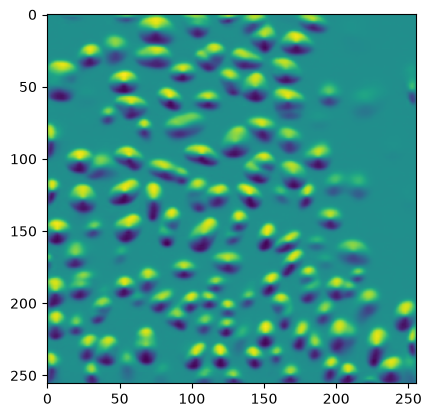

In [197]:
plt.imshow(flows[1][0][1])

In [ ]:
segmentation_3d, (probability_3d, gradients_3d) = uSegment3D.aggregate_2D_to_3D_segmentation_direct_method(
    probs=[flows[2], [] ,[]],
    gradients=[flows[1], [] ,[]], 
    params=aggregation_params,
    savefolder=None,
    basename=None)

/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/segment3D/usegment3d.py:277: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_binary = skmorph.binary_closing(mask_binary, skmorph.ball(params['postprocess_binary']['binary_closing']))
/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/segment3D/usegment3d.py:279: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_binary = skmorph.remove_small_objects(mask_binary,
/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/segment3D/usegment3d.py:283: FutureWarning: `binary_d

In [188]:
indirect_aggregation_params = uSegment3D_params.get_2D_to_3D_aggregation_params()

# since we are going to combine on binaries 
indirect_aggregation_params['indirect_method']['smooth_sigma'] = 0 # we can add some smoothing filter first. 

indirect_aggregation_params['combine_cell_probs']['ksize'] = 1
indirect_aggregation_params['combine_cell_probs']['alpha'] = 0.5 
indirect_aggregation_params['combine_cell_probs']['smooth_sigma'] = 0 # add post smoothing too after combine 
indirect_aggregation_params['combine_cell_probs']['prob_thresh'] = 0.1

# choice of transforms and its computation parameters:
indirect_aggregation_params['indirect_method']['dtform_method'] = 'cellpose_improve' # this will use our exact solver of heat equation. with a fixed central point
indirect_aggregation_params['indirect_method']['edt_fixed_point_percentile'] = 0.01 # adjust the medial centroid placement


indirect_aggregation_params['gradient_descent']['n_iter'] = 200 
indirect_aggregation_params['gradient_descent']['gradient_decay'] = 0.001 # increase this to alleviate splitting of elongated/branching structures with cellpose gradients or decrease towards 0.0 to encourage splitting. 
indirect_aggregation_params['gradient_descent']['momenta'] = 0.98 # help boost the splitting 
indirect_aggregation_params['combine_cell_probs']['threshold_n_levels'] = 2
indirect_aggregation_params['combine_cell_probs']['threshold_level'] = -1
indirect_aggregation_params['combine_cell_probs']['min_prob_thresh'] = 0.5

In [189]:
segmentation_3d, (probability_3d, gradients_3d) = (
    uSegment3D.aggregate_2D_to_3D_segmentation_indirect_method(
        segmentations=[masks, [], []],
        img_xy_shape=img.shape,
        precomputed_binary=None,
        params=indirect_aggregation_params,
        savefolder=None,
        basename=None,
    )
)

/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/segment3D/usegment3d.py:543: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  mask_binary = skmorph.binary_closing(mask_binary, skmorph.ball(params['postprocess_binary']['binary_closing']))
/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/segment3D/usegment3d.py:545: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_binary = skmorph.remove_small_objects(mask_binary,
/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/segment3D/usegment3d.py:549: FutureWarning: `binary_d

In [190]:
ids = np.unique(segmentation_3d)
ids = ids[ids > 0]
seeds = ndimage.center_of_mass(segmentation_3d > 0, segmentation_3d, ids)
seeds = np.round(np.asarray(seeds))

print('Found', len(seeds), 'cells')

Found 198 cells


In [191]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    seeds,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 15 out of 19 GT nodes


/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/cellpose/utils.py:203: RuntimeWarning: invalid value encountered in cast
  slices = find_objects(masks.astype(int))


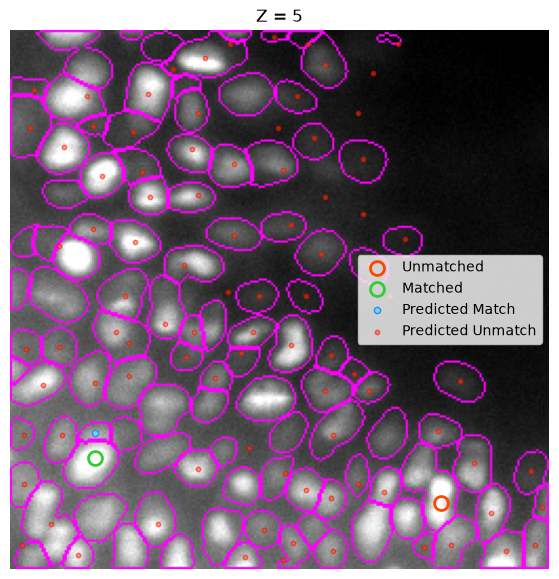

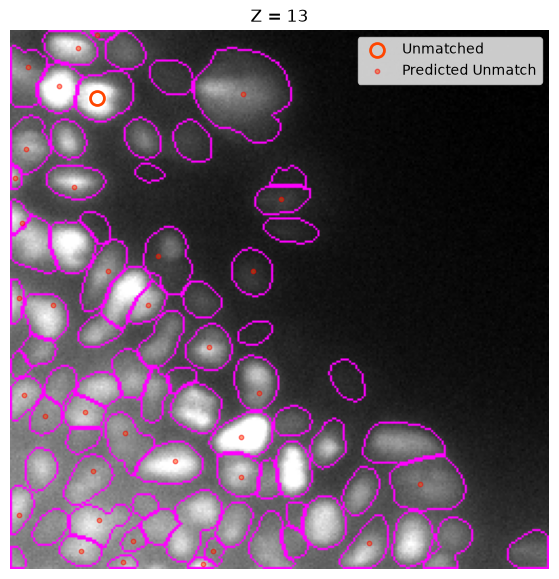

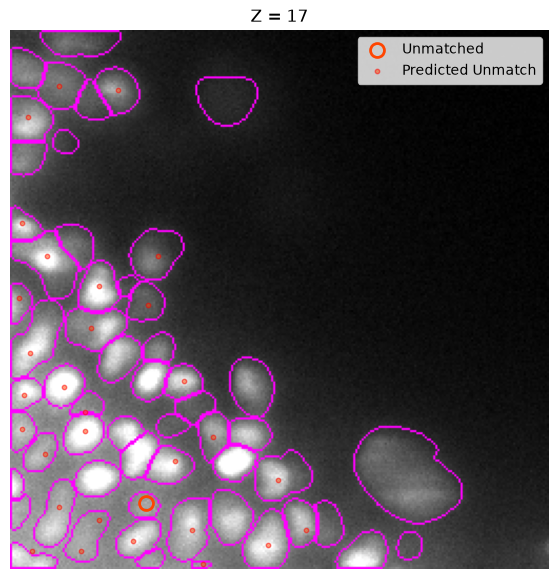

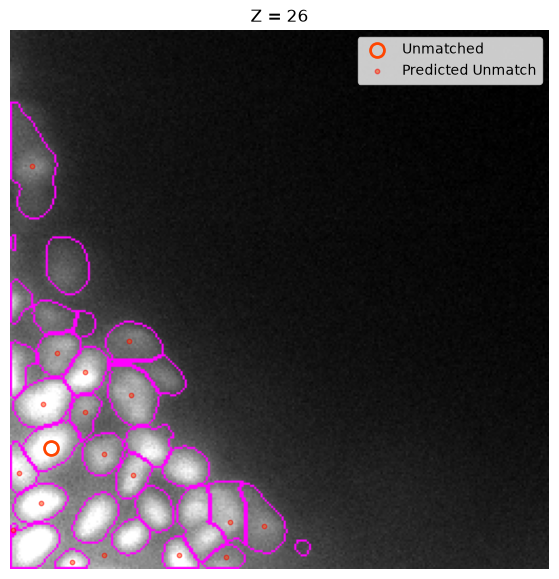

In [192]:
mask = np.where(segmentation_3d > 0, segmentation_3d, np.nan)
tol = 3

ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else [7]
# ids = np.unique(gt[:, 0])

for i in ids:    
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plot_contours(img[i], mask[i])
    # break
    scatter_plot_center_preds(seeds, matched_gt, unmatched_gt, frame=i, tol=tol)
    plt.show()

    # break

In [151]:
interactive_center_preds(
    img,
    seeds,
    matched_gt,
    unmatched_gt,
    mask=segmentation_3d,
    tol=tol,
    figsize=(6, 6),
)

## 4. Postprocess the 3D segmentation and extract centers

In [116]:
postprocess_3d_params = uSegment3D_params.get_postprocess_segmentation_params()
postprocess_3d_params["size_filters"]["min_size"] = 200
postprocess_3d_params["size_filters"]["do_stats_filter"] = True
postprocess_3d_params["do_flow_remove"] = True

segmentation_3d_filt, flow_consistency_intermediates = (
    uSegment3D.postprocess_3D_cell_segmentation(
        segmentation_3d,
        aggregation_params=aggregation_params,
        postprocess_params=postprocess_3d_params,
        cell_gradients=gradients_3d,
        savefolder=None,
        basename=None,
    )
)

print("Postprocessed 3D instances:", int(segmentation_3d_filt.max()))

finish yz
finished computing gradients and removing bad flow masks ...
Postprocessed 3D instances: 181


In [117]:
# Tighten loose instance boundaries with the bright 3D foreground, as in the
# u-Segment3D reference example.
img_smooth = ndimage.gaussian_filter(img_preprocess, sigma=1)
foreground = img_smooth >= skfilters.threshold_multiotsu(img_smooth, 3)[-1]
foreground = skmorph.binary_closing(foreground, skmorph.ball(3))

masks_3d = segmentation_3d_filt * foreground
masks_3d = uSegment3D_filters.largest_component_vol_labels_fast(masks_3d)

label_ids = np.setdiff1d(np.unique(masks_3d), 0)
seeds = np.asarray(
    ndimage.center_of_mass(masks_3d > 0, labels=masks_3d, index=label_ids)
)

print("Final 3D instances:", len(label_ids))
print("Seeds shape (z, y, x):", seeds.shape)

/tmp/ipykernel_24129/3036176033.py:5: FutureWarning: `binary_closing` is deprecated since version 0.26 and will be removed in version 0.28. Use `skimage.morphology.closing` instead.
  foreground = skmorph.binary_closing(foreground, skmorph.ball(3))


167
Final 3D instances: 167
Seeds shape (z, y, x): (167, 3)


In [118]:
ids = np.unique(segmentation_3d)
ids = ids[ids > 0]
seeds = ndimage.center_of_mass(segmentation_3d > 0, segmentation_3d, ids)
seeds = np.round(np.asarray(seeds))

print('Found', len(seeds), 'cells')

Found 188 cells


In [119]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    seeds,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 14 out of 19 GT nodes


/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/cellpose/utils.py:203: RuntimeWarning: invalid value encountered in cast
  slices = find_objects(masks.astype(int))


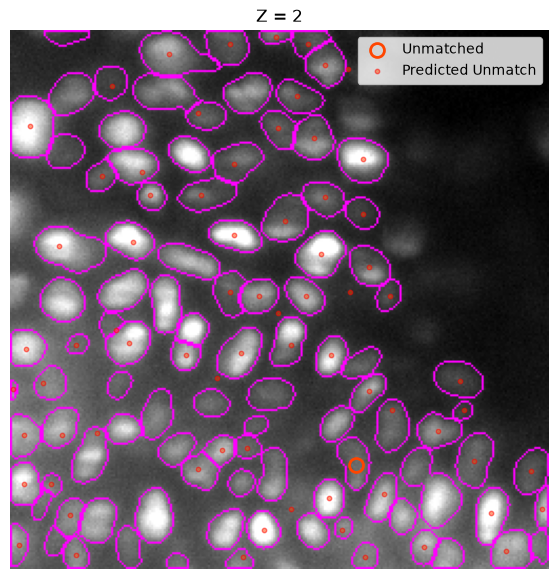

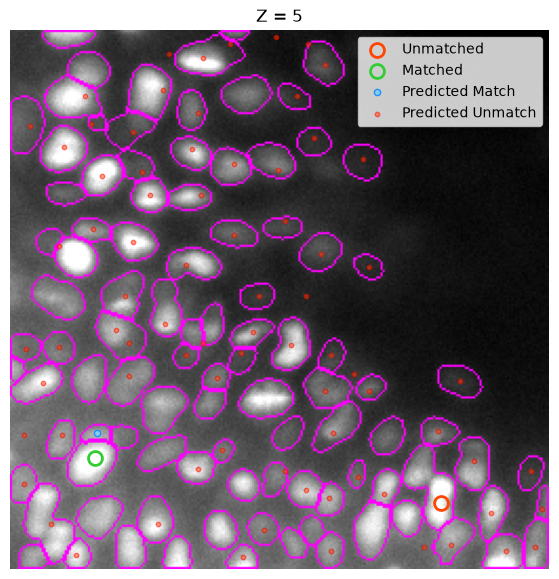

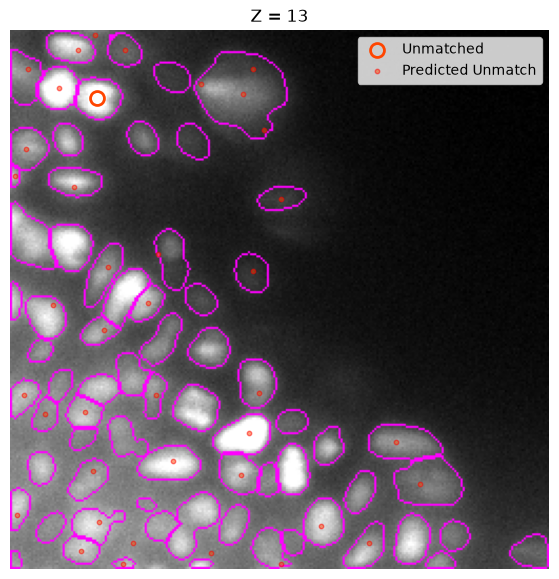

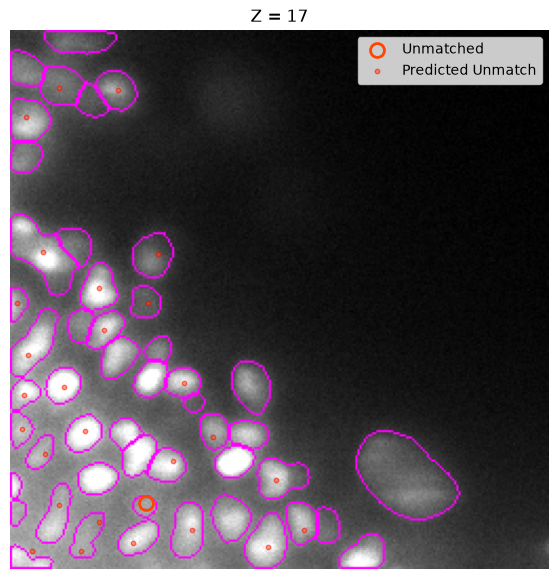

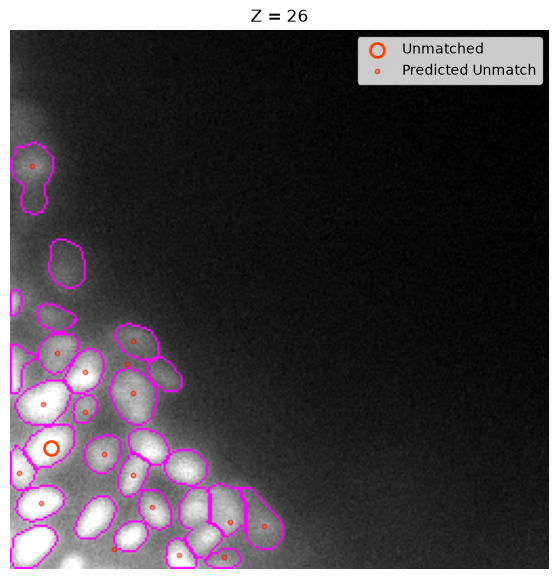

In [120]:
mask = np.where(segmentation_3d > 0, segmentation_3d, np.nan)
tol = 3

ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else []
# ids = np.unique(gt[:, 0])

for i in ids:    
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plot_contours(img[i], mask[i])
    # break
    scatter_plot_center_preds(seeds, matched_gt, unmatched_gt, frame=i, tol=tol)
    plt.show()

    # break

In [ ]:
interactive_center_preds(
    img,
    seeds,
    matched_gt,
    unmatched_gt,
    mask=segmentation_3d,
    tol=tol,
    figsize=(6, 6),
)